In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import statistics
import warnings
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import geopandas as gpd
from pathlib import Path
import os

# Ignore all warnings
warnings.filterwarnings("ignore")

In [2]:

from pathlib import Path

root = Path("/kaggle/input")

for file in root.rglob("*"):
    if file.is_file():
        print(
            file.relative_to(root),
            "|",
            round(file.stat().st_size / 1024 / 1024, 2),
            "MB"
        )


datasets/abdulhamidaleyrashid/documentations/00.geojson | 4.41 MB
datasets/abdulhamidaleyrashid/documentations/Documentation.pdf | 0.06 MB
datasets/abdulhamidaleyrashid/documentations/Readme.pdf | 0.02 MB


In [3]:
# Locate the dataset
files = list(
    Path("/kaggle/input").rglob("00.geojson")
)

if not files:
    raise FileNotFoundError("00.geojson not found")

data_path = files[0]
print("Dataset:", data_path)

# Load geographic reference data
gdf = gpd.read_file(data_path)

print("Total features:", len(gdf))
print("Coordinate system:", gdf.crs)
print("Columns:", gdf.columns.tolist())

display(gdf.head())


Dataset: /kaggle/input/datasets/abdulhamidaleyrashid/documentations/00.geojson
Total features: 1851
Coordinate system: EPSG:32631
Columns: ['OBJECTID', 'class', 'Shape_Leng', 'Shape_Area', 'class_name', 'geometry']


,OBJECTID,class,Shape_Leng,Shape_Area,class_name,geometry
0,1,1,367629.523311,1.699754e+07,Well-managed planatation,"POLYGON ((447131.215 1001286.636, 447166.272 1..."
1,1,1,367629.523311,1.699754e+07,Well-managed planatation,"POLYGON ((444422.669 1001301.178, 444399.641 1..."
2,1,1,367629.523311,1.699754e+07,Well-managed planatation,"POLYGON ((444533.265 1001236.884, 444530.617 1..."
3,1,1,367629.523311,1.699754e+07,Well-managed planatation,"POLYGON ((443708.293 1001345.628, 443701.144 1..."
4,1,1,367629.523311,1.699754e+07,Well-managed planatation,"POLYGON ((441946.507 1001392.384, 441975.082 1..."


In [4]:

class_names = {
    1: "Well-managed cashew",
    2: "Poorly-managed cashew",
    3: "Non-plantation",
    4: "Residential",
    5: "Background",
    6: "Uncertain"
}

print("Class distribution:")
print(gdf["class"].value_counts().sort_index())

gdf["class_name"] = (
    gdf["class"]
    .map(class_names)
    .fillna("Unknown")
)

display(gdf[["class", "class_name"]].head())


Class distribution:
class
1    381
2    629
3    470
4    112
5    197
6     62
Name: count, dtype: int64


,class,class_name
0,1,Well-managed cashew
1,1,Well-managed cashew
2,1,Well-managed cashew
3,1,Well-managed cashew
4,1,Well-managed cashew


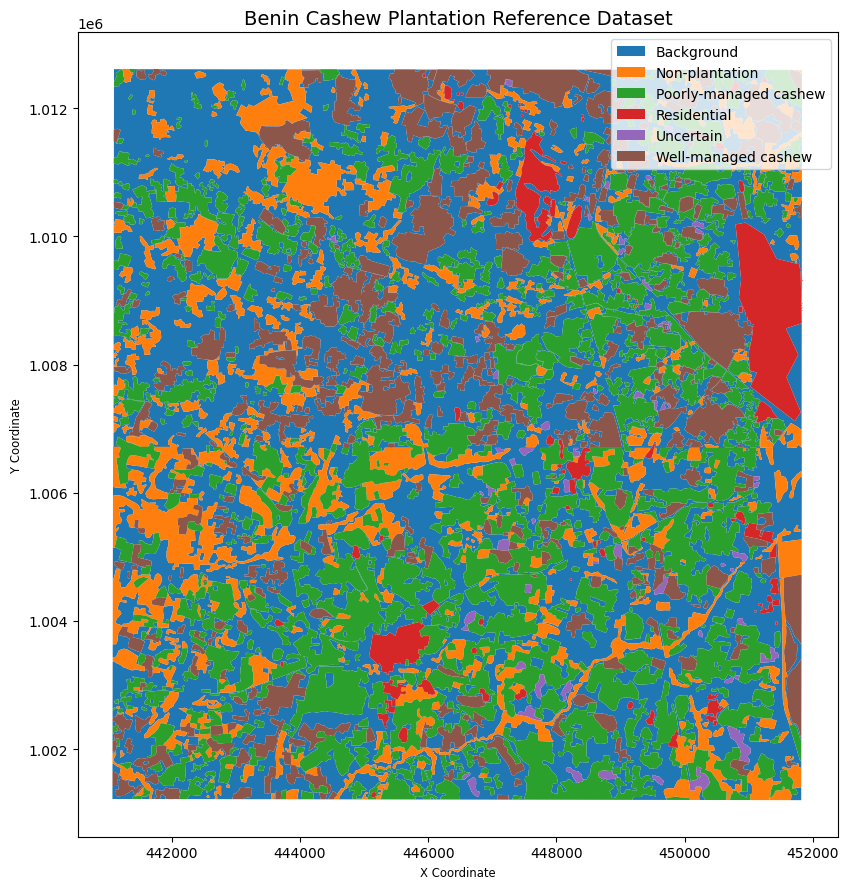

In [5]:

fig, ax = plt.subplots(figsize=(12, 9))

gdf.plot(
    ax=ax,
    column="class_name",
    categorical=True,
    legend=True,
    cmap="tab10",
    linewidth=0
)

ax.set_title(
    "Benin Cashew Plantation Reference Dataset",
    fontsize=14
)

ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")

plt.tight_layout()
plt.show()


In [6]:

print("Missing values:")
display(gdf.isnull().sum())

print("Invalid geometries:",
      (~gdf.geometry.is_valid).sum())

print("Empty geometries:",
      gdf.geometry.is_empty.sum())

print("Duplicate geometries:",
      gdf.geometry.to_wkb().duplicated().sum())

# Convert to projected CRS for area calculations
gdf_projected = gdf.to_crs("EPSG:32631")

gdf_projected["area_ha"] = (
    gdf_projected.geometry.area / 10000
)

display(
    gdf_projected.groupby("class_name")["area_ha"]
    .agg(["count", "sum", "mean"])
    .round(3)
)


Missing values:


OBJECTID      0
class         0
Shape_Leng    0
Shape_Area    0
class_name    0
geometry      0
dtype: int64

Invalid geometries: 9
Empty geometries: 0
Duplicate geometries: 0


,count,sum,mean
class_name,,,
Background,197,5098.137,25.879
Non-plantation,470,1633.513,3.476
Poorly-managed cashew,629,3309.247,5.261
Residential,112,412.603,3.684
Uncertain,62,87.119,1.405
Well-managed cashew,381,1699.754,4.461


Identify the nine invalid polygons

In [7]:

from shapely.validation import explain_validity

invalid = gdf.loc[~gdf.geometry.is_valid].copy()

invalid["problem"] = invalid.geometry.apply(
    explain_validity
)

display(
    invalid[
        ["OBJECTID", "class", "class_name", "problem"]
    ]
)

print("Invalid polygons by class:")
print(invalid["class_name"].value_counts())

,OBJECTID,class,class_name,problem
336,1,1,Well-managed cashew,Ring Self-intersection[441723.2305 1011269.9688]
413,2,2,Poorly-managed cashew,Ring Self-intersection[441293.1664 1001786.6527]
471,2,2,Poorly-managed cashew,Ring Self-intersection[441730.2263 1002904.8379]
573,2,2,Poorly-managed cashew,Ring Self-intersection[445786.3476 1004665.0203]
622,2,2,Poorly-managed cashew,Ring Self-intersection[450106.5536 1005431.2485]
736,2,2,Poorly-managed cashew,Ring Self-intersection[441844.7326 1007529.6274]
1144,3,3,Non-plantation,Ring Self-intersection[442560.4021 1004630.4649]
1193,3,3,Non-plantation,Ring Self-intersection[444993.0755 1005645.6859]
1787,5,5,Background,Ring Self-intersection[451811.4864 1009399.6044]


Invalid polygons by class:
class_name
Poorly-managed cashew    5
Non-plantation           2
Well-managed cashew      1
Background               1
Name: count, dtype: int64


Repair geometries, preserving the original data

In [8]:

from shapely import make_valid

gdf_clean = gdf.copy()

# Repair only invalid geometries
mask = ~gdf_clean.geometry.is_valid

gdf_clean.loc[mask, "geometry"] = (
    gdf_clean.loc[mask, "geometry"]
    .apply(make_valid)
)

print("Remaining invalid geometries:",
      (~gdf_clean.geometry.is_valid).sum())

print("Geometry types after repair:")
print(gdf_clean.geometry.geom_type.value_counts())

print("Original features:", len(gdf))
print("Repaired features:", len(gdf_clean))

Remaining invalid geometries: 0
Geometry types after repair:
Polygon    1851
Name: count, dtype: int64
Original features: 1851
Repaired features: 1851


Create a binary cashew classification target

In [9]:

# Exclude uncertain reference labels
gdf_binary = gdf_clean[
    gdf_clean["class"].isin([1, 2, 3, 4, 5])
].copy()

gdf_binary["target"] = (
    gdf_binary["class"].isin([1, 2]).astype(int)
)

print("Binary target distribution:")
print(gdf_binary["target"].value_counts())

print("Excluded uncertain features:",
      len(gdf_clean) - len(gdf_binary))

Binary target distribution:
target
1    1010
0     779
Name: count, dtype: int64
Excluded uncertain features: 62


Check whether the geometry repairs changed polygon areas

In [10]:

repaired_mask = ~gdf.geometry.is_valid

before = gdf.loc[repaired_mask].geometry.area
after = gdf_clean.loc[repaired_mask].geometry.area

repair_report = pd.DataFrame({
    "class": gdf.loc[repaired_mask, "class"],
    "area_before_m2": before,
    "area_after_m2": after
})

repair_report["area_change_pct"] = np.where(
    repair_report["area_before_m2"] > 0,
    100 * (
        repair_report["area_after_m2"] -
        repair_report["area_before_m2"]
    ) / repair_report["area_before_m2"],
    np.nan
)

display(repair_report.round(3))


,class,area_before_m2,area_after_m2,area_change_pct
336,1,1.383628e+04,1.383628e+04,0.0
413,2,1.236631e+04,1.236631e+04,-0.0
471,2,6.485710e+04,6.485710e+04,0.0
573,2,1.475098e+06,1.475098e+06,0.0
622,2,9.565052e+05,9.565052e+05,-0.0
736,2,2.171849e+05,2.171849e+05,0.0
1144,3,8.266382e+04,8.266382e+04,-0.0
1193,3,2.136235e+05,2.136235e+05,0.0
1787,5,4.686658e+07,4.686658e+07,-0.0


Checking whether polygons overlap

In [11]:

from shapely.strtree import STRtree

geoms = gdf_binary.geometry.to_list()
tree = STRtree(geoms)

overlaps = []

for i, geom in enumerate(geoms):
    for j in tree.query(geom, predicate="intersects"):
        j = int(j)

        if j <= i:
            continue

        intersection_area = geom.intersection(geoms[j]).area

        if intersection_area > 1:
            overlaps.append({
                "polygon_a": i,
                "polygon_b": j,
                "class_a": int(gdf_binary.iloc[i]["class"]),
                "class_b": int(gdf_binary.iloc[j]["class"]),
                "overlap_m2": intersection_area
            })

overlap_df = pd.DataFrame(overlaps)

print("Overlapping polygon pairs:", len(overlap_df))

if not overlap_df.empty:
    print(
        "Pairs involving different classes:",
        (overlap_df["class_a"] != overlap_df["class_b"]).sum()
    )
    display(
        overlap_df.sort_values(
            "overlap_m2", ascending=False
        ).head(10)
    )


Overlapping polygon pairs: 207
Pairs involving different classes: 207


,polygon_a,polygon_b,class_a,class_b,overlap_m2
47,664,1787,2,5,9502.816209
97,1266,1787,3,5,6699.926575
72,690,1787,2,5,6651.163841
70,688,1787,2,5,6147.035228
51,667,1787,2,5,4919.234255
63,675,1787,2,5,4701.827360
95,1252,1787,3,5,4692.138262
87,1239,1787,3,5,3282.993835
49,666,1787,2,5,2344.319495
84,1237,1787,3,5,2081.818076


In [12]:
output_dir = Path("/kaggle/working/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "benin_cashew_binary.geojson"

gdf_binary.to_file(
    output_file,
    driver="GeoJSON"
)

print("Saved:", output_file)


Saved: /kaggle/working/processed/benin_cashew_binary.geojson


Analyze binary-label conflicts

In [13]:

# We already created overlap_df
report = overlap_df.copy()

report["target_a"] = report["class_a"].isin(
    [1, 2]
).astype(int)

report["target_b"] = report["class_b"].isin(
    [1, 2]
).astype(int)

report["binary_conflict"] = (
    report["target_a"] != report["target_b"]
)

report["involves_background"] = (
    (report["class_a"] == 5) |
    (report["class_b"] == 5)
)

print("Total overlapping pairs:", len(report))

print(
    "Binary conflicts:",
    report["binary_conflict"].sum()
)

print(
    "Same binary target:",
    (~report["binary_conflict"]).sum()
)

print(
    "Pairs involving background:",
    report["involves_background"].sum()
)

print(
    "Binary conflicts involving background:",
    (
        report["binary_conflict"] &
        report["involves_background"]
    ).sum()
)

display(
    report.groupby(
        ["class_a", "class_b", "binary_conflict"]
    ).agg(
        pairs=("overlap_m2", "size"),
        summed_overlap_m2=("overlap_m2", "sum")
    ).reset_index()
)


Total overlapping pairs: 207
Binary conflicts: 68
Same binary target: 139
Pairs involving background: 145
Binary conflicts involving background: 19


,class_a,class_b,binary_conflict,pairs,summed_overlap_m2
0,1,2,False,5,3611.021300
1,1,3,True,1,165.354680
2,1,4,True,5,74.478722
3,1,5,True,3,232.327254
4,2,3,True,9,3577.272169
5,2,4,True,34,347.272475
6,2,5,True,16,44794.039018
7,3,4,False,8,73.704584
8,3,5,False,18,26361.879562
9,4,5,False,108,2370.999900


Check whether uncertain polygons intersect training labels

In [14]:

from shapely.ops import unary_union

uncertain = gdf_clean[
    gdf_clean["class"] == 6
].copy()

uncertain_union = unary_union(
    uncertain.geometry.tolist()
)

affected = gdf_binary.geometry.intersects(
    uncertain_union
)

print("Uncertain polygons:", len(uncertain))

print(
    "Training polygons intersecting uncertain regions:",
    affected.sum()
)

print(
    "Uncertain area (hectares):",
    round(uncertain_union.area / 10000, 2)
)

display(
    gdf_binary.loc[
        affected, ["class", "class_name", "target"]
    ].groupby(
        ["class", "class_name", "target"]
    ).size()
)


Uncertain polygons: 62
Training polygons intersecting uncertain regions: 46
Uncertain area (hectares): 87.12


class  class_name             target
1      Well-managed cashew    1          7
2      Poorly-managed cashew  1         17
3      Non-plantation         0          7
4      Residential            0          1
5      Background             0         14
dtype: int64

Construct mutually exclusive cashew and non-cashew regions

In [15]:

import shapely
from shapely import make_valid

# Use repaired geometries from previous steps.
# The source CRS is EPSG:32631 (metres).
assert gdf_clean.crs is not None
assert gdf_clean.crs.is_projected

cashew = gdf_clean[
    gdf_clean["class"].isin([1, 2])
]

non_cashew = gdf_clean[
    gdf_clean["class"].isin([3, 4, 5])
]

uncertain = gdf_clean[
    gdf_clean["class"] == 6
]

# Combine polygon coverage within each binary group
cashew_union = shapely.union_all(
    cashew.geometry.to_numpy()
)

non_cashew_union = shapely.union_all(
    non_cashew.geometry.to_numpy()
)

uncertain_union = shapely.union_all(
    uncertain.geometry.to_numpy()
)

# Regions where both binary classes claim the same area
conflict = cashew_union.intersection(
    non_cashew_union
)

# Remove ambiguous and uncertain coverage
cashew_clean = make_valid(
    cashew_union.difference(non_cashew_union)
    .difference(uncertain_union)
)

non_cashew_clean = make_valid(
    non_cashew_union.difference(cashew_union)
    .difference(uncertain_union)
)

print("Cashew area (ha):",
      round(cashew_clean.area / 10000, 2))

print("Non-cashew area (ha):",
      round(non_cashew_clean.area / 10000, 2))

print("Conflicting area (ha):",
      round(conflict.area / 10000, 2))

print("Remaining intersection (m²):",
      cashew_clean.intersection(
          non_cashew_clean
      ).area)


Cashew area (ha): 5003.72
Non-cashew area (ha): 7135.91
Conflicting area (ha): 4.92
Remaining intersection (m²): 0.0


Save the cleaned spatial reference layer

In [16]:
# Both categories may contain multipart geometry.
clean_labels = gpd.GeoDataFrame(
    {
        "target": [1, 0],
        "label": ["Cashew", "Non-cashew"]
    },
    geometry=[cashew_clean, non_cashew_clean],
    crs=gdf_clean.crs
)

output_dir = Path("/kaggle/working/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "benin_binary_conflict_free.geojson"
)

clean_labels.to_file(
    output_path,
    driver="GeoJSON"
)

print("Saved:", output_path)
display(clean_labels)


Saved: /kaggle/working/processed/benin_binary_conflict_free.geojson


,target,label,geometry
0,1,Cashew,"MULTIPOLYGON (((441421.077 1001279.159, 441429..."
1,0,Non-cashew,"MULTIPOLYGON (((441661.914 1001296.057, 441667..."


Produce the map

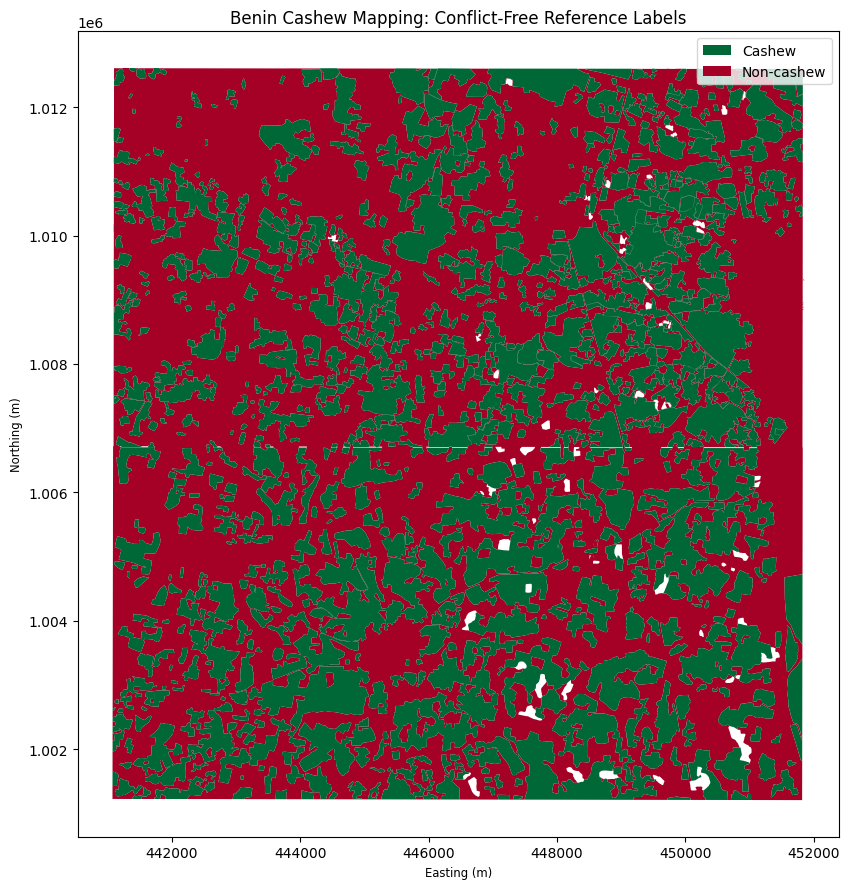

In [17]:

from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 9))

clean_labels.plot(
    column="target",
    categorical=True,
    cmap="RdYlGn",
    linewidth=0,
    ax=ax,
    legend=False
)

ax.set_title(
    "Benin Cashew Mapping: Conflict-Free Reference Labels"
)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

ax.legend(handles=[
    Patch(facecolor="#006837", label="Cashew"),
    Patch(facecolor="#a50026", label="Non-cashew")
])

plt.tight_layout()
plt.show()
